In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("AI_Fresher_Recruitment_ML_Dataset.csv")

In [3]:
df.head()

,Application ID,Candidate ID,Job ID,Job Role,Degree,Specialization,CGPA,Class 10 Percentage,Class 12 Percentage,Backlogs,...,Achievement_Count,Backlog_Score,Project_Score,Internship_Score,Certification_Score,Achievement_Score,Recruitment_Score,Rank,Shortlist Limit,Shortlisted
0,APP_00001,CND_00001,JOB_001,AI/ML Engineer,B.E,Computer Science,8.12,83.79,88.65,0.0,...,2.0,1.000000,0.0,0.25,0.6,0.50,50.63,2561,35,0
1,APP_00002,CND_00002,JOB_003,Software Engineer,B.Tech,Data Science,8.99,92.16,97.01,0.0,...,1.0,1.000000,0.2,0.25,0.6,0.25,54.95,2079,70,0
2,APP_00003,CND_00003,JOB_002,Data Analyst,BCA,Artificial Intelligence,7.30,81.28,76.94,0.0,...,1.0,1.000000,0.6,0.50,0.4,0.25,60.65,1653,52,0
3,APP_00004,CND_00004,JOB_002,Data Analyst,B.E,Artificial Intelligence,7.30,65.53,84.03,0.0,...,1.0,1.000000,0.6,0.50,0.6,0.25,63.40,1218,52,0
4,APP_00005,CND_00005,JOB_002,Data Analyst,BCA,Data Science,6.84,76.81,71.25,1.0,...,0.0,0.833333,0.8,0.25,0.4,0.00,50.43,3189,52,0


In [4]:
df.shape

(16508, 41)

In [5]:
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)


Column Names:
['Application ID', 'Candidate ID', 'Job ID', 'Job Role', 'Degree', 'Specialization', 'CGPA', 'Class 10 Percentage', 'Class 12 Percentage', 'Backlogs', 'Skills', 'Number of Projects', 'Projects', 'Number of Internships', 'Internships', 'Number of Certifications', 'Certifications', 'Number of Achievements', 'Achievements', 'Number of Openings', 'Required Skills', 'Preferred Degree', 'Minimum CGPA', 'CGPA_Score', 'CGPA_Eligible', 'CGPA_Gap', 'Degree_Match', 'Skill_Match', 'Project_Count', 'Internship_Count', 'Certification_Count', 'Achievement_Count', 'Backlog_Score', 'Project_Score', 'Internship_Score', 'Certification_Score', 'Achievement_Score', 'Recruitment_Score', 'Rank', 'Shortlist Limit', 'Shortlisted']

Data Types:
Application ID               object
Candidate ID                 object
Job ID                       object
Job Role                     object
Degree                       object
Specialization               object
CGPA                        float64
Clas

In [6]:
df.isnull().sum()

Application ID              0
Candidate ID                0
Job ID                      0
Job Role                    0
Degree                      0
Specialization              0
CGPA                        0
Class 10 Percentage         0
Class 12 Percentage         0
Backlogs                    0
Skills                      0
Number of Projects          0
Projects                    0
Number of Internships       0
Internships                 0
Number of Certifications    0
Certifications              0
Number of Achievements      0
Achievements                0
Number of Openings          0
Required Skills             0
Preferred Degree            0
Minimum CGPA                0
CGPA_Score                  0
CGPA_Eligible               0
CGPA_Gap                    0
Degree_Match                0
Skill_Match                 0
Project_Count               0
Internship_Count            0
Certification_Count         0
Achievement_Count           0
Backlog_Score               0
Project_Sc

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["Shortlisted"].value_counts()

Shortlisted
0    16299
1      209
Name: count, dtype: int64

In [9]:
df["Shortlisted"].value_counts(normalize=True).mul(100).round(2)

Shortlisted
0    98.73
1     1.27
Name: proportion, dtype: float64

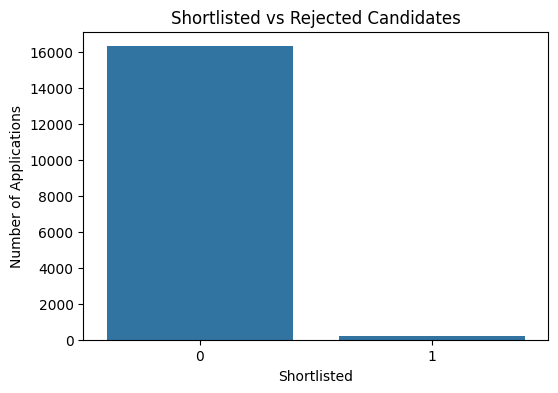

In [10]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Shortlisted"
)

plt.title("Shortlisted vs Rejected Candidates")
plt.xlabel("Shortlisted")
plt.ylabel("Number of Applications")
plt.show()

In [11]:
df["Job Role"].value_counts()

Job Role
Software Engineer    4190
AI/ML Engineer       4161
Data Analyst         4110
Python Developer     4047
Name: count, dtype: int64

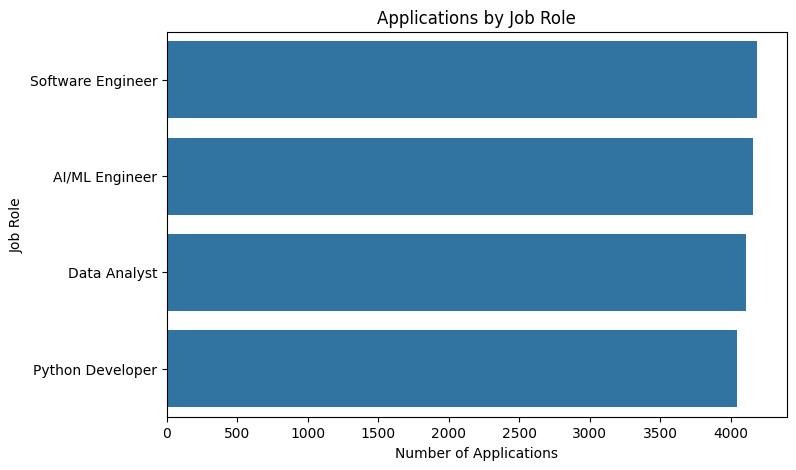

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    y="Job Role",
    order=df["Job Role"].value_counts().index
)

plt.title("Applications by Job Role")
plt.xlabel("Number of Applications")
plt.ylabel("Job Role")
plt.show()

In [13]:
shortlist_by_job = (
    df.groupby("Job Role")["Shortlisted"]
    .sum()
    .sort_values(ascending=False)
)

print(shortlist_by_job)

Job Role
Software Engineer    70
Data Analyst         52
Python Developer     52
AI/ML Engineer       35
Name: Shortlisted, dtype: int64


In [14]:
job_summary = (
    df.groupby("Job Role")
    .agg(
        Applications=("Application ID", "count"),
        Openings=("Number of Openings", "first"),
        Shortlisted=("Shortlisted", "sum")
    )
)

job_summary["Expected Shortlist"] = (
    job_summary["Openings"] * 3.5
).round().astype(int)

job_summary

,Applications,Openings,Shortlisted,Expected Shortlist
Job Role,,,,
AI/ML Engineer,4161,10,35,35
Data Analyst,4110,15,52,52
Python Developer,4047,15,52,52
Software Engineer,4190,20,70,70


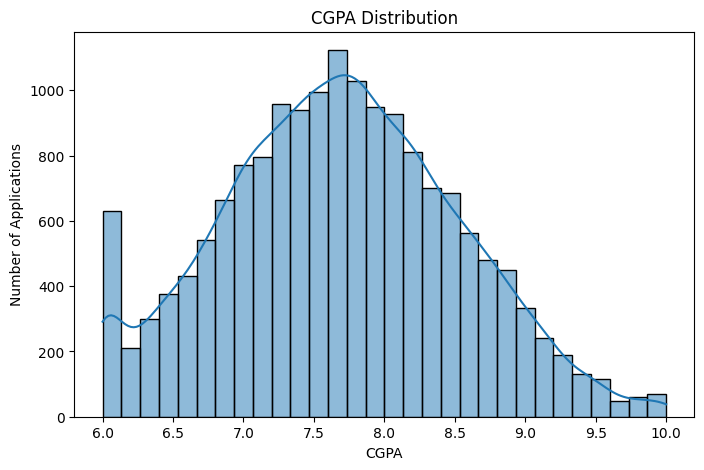

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="CGPA",
    bins=30,
    kde=True
)

plt.title("CGPA Distribution")
plt.xlabel("CGPA")
plt.ylabel("Number of Applications")
plt.show()

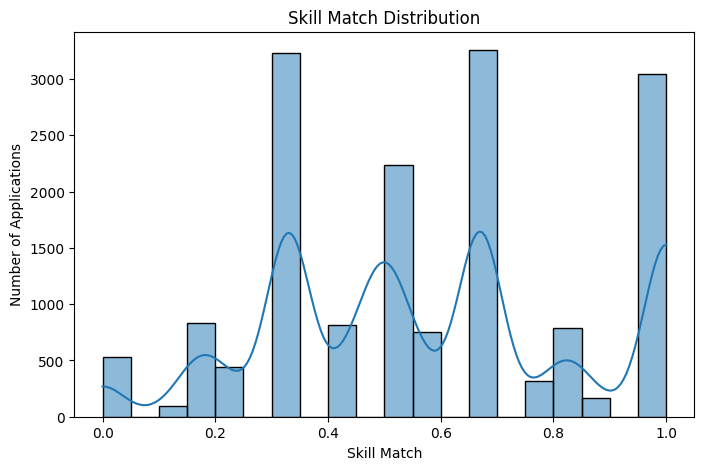

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Skill_Match",
    bins=20,
    kde=True
)

plt.title("Skill Match Distribution")
plt.xlabel("Skill Match")
plt.ylabel("Number of Applications")
plt.show()

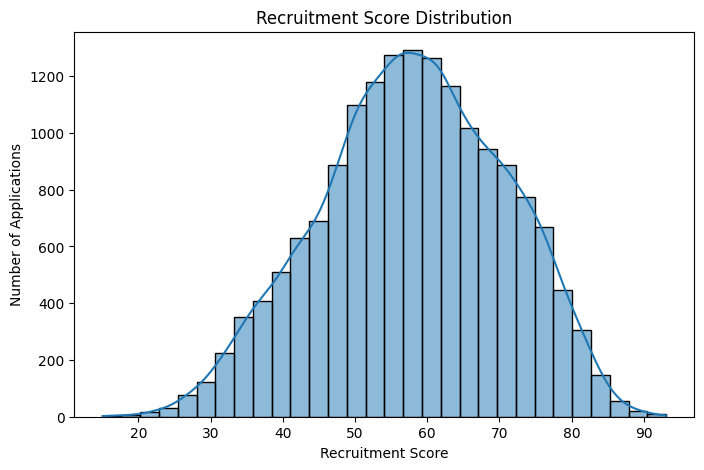

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Recruitment_Score",
    bins=30,
    kde=True
)

plt.title("Recruitment Score Distribution")
plt.xlabel("Recruitment Score")
plt.ylabel("Number of Applications")
plt.show()

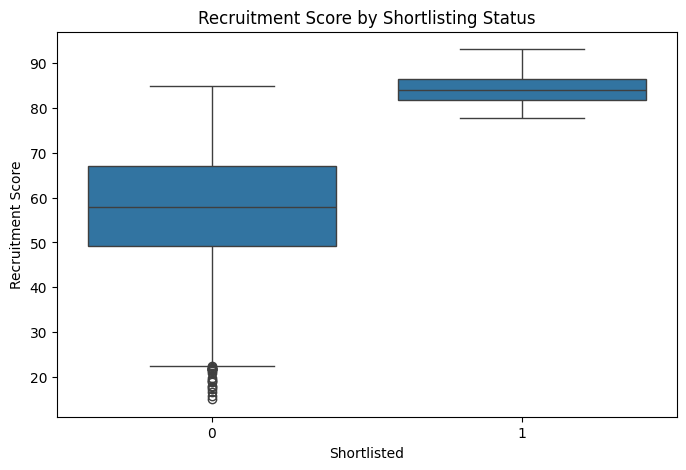

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Shortlisted",
    y="Recruitment_Score"
)

plt.title("Recruitment Score by Shortlisting Status")
plt.xlabel("Shortlisted")
plt.ylabel("Recruitment Score")
plt.show()

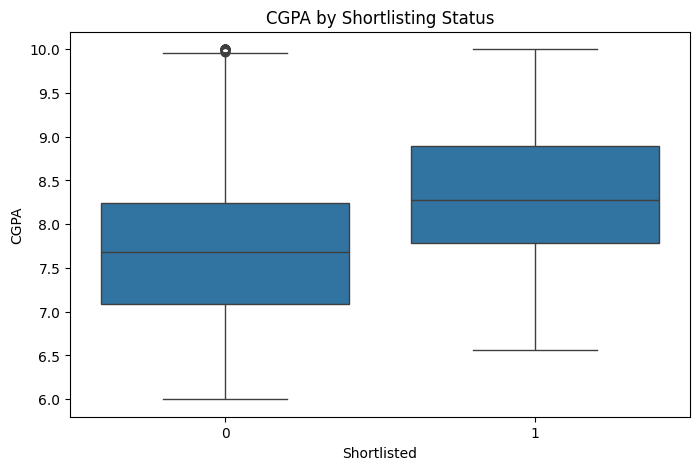

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Shortlisted",
    y="CGPA"
)

plt.title("CGPA by Shortlisting Status")
plt.xlabel("Shortlisted")
plt.ylabel("CGPA")
plt.show()

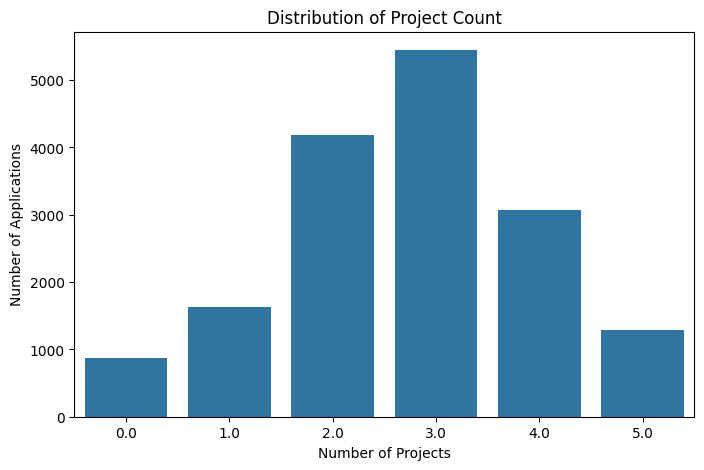

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Project_Count"
)

plt.title("Distribution of Project Count")
plt.xlabel("Number of Projects")
plt.ylabel("Number of Applications")
plt.show()

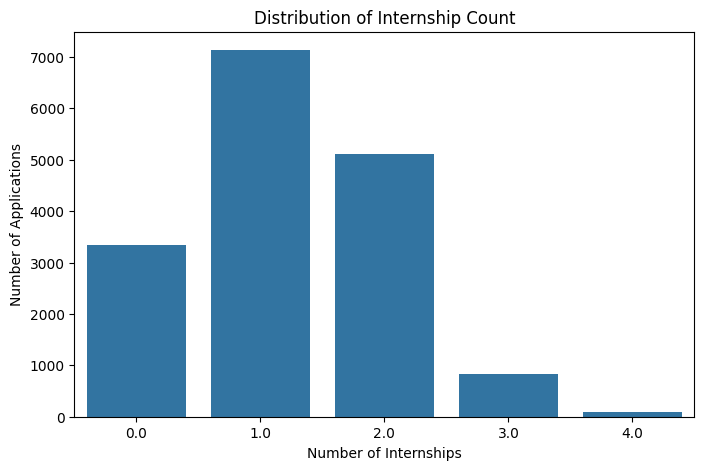

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Internship_Count"
)

plt.title("Distribution of Internship Count")
plt.xlabel("Number of Internships")
plt.ylabel("Number of Applications")
plt.show()

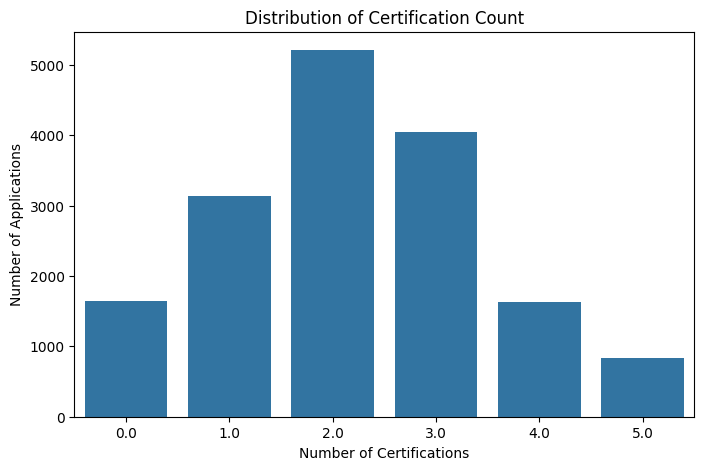

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Certification_Count"
)

plt.title("Distribution of Certification Count")
plt.xlabel("Number of Certifications")
plt.ylabel("Number of Applications")
plt.show()

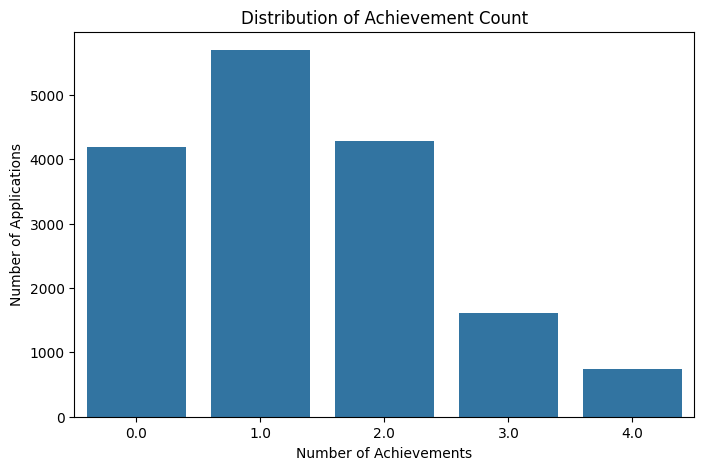

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Achievement_Count"
)

plt.title("Distribution of Achievement Count")
plt.xlabel("Number of Achievements")
plt.ylabel("Number of Applications")
plt.show()

In [24]:
numeric_features = [
    "CGPA",
    "Class 10 Percentage",
    "Class 12 Percentage",
    "Backlogs",
    "Skill_Match",
    "Project_Count",
    "Internship_Count",
    "Certification_Count",
    "Achievement_Count",
    "CGPA_Score",
    "Degree_Match",
    "Backlog_Score",
    "Project_Score",
    "Internship_Score",
    "Certification_Score",
    "Achievement_Score",
    "Recruitment_Score",
    "Shortlisted"
]

correlation = df[numeric_features].corr()

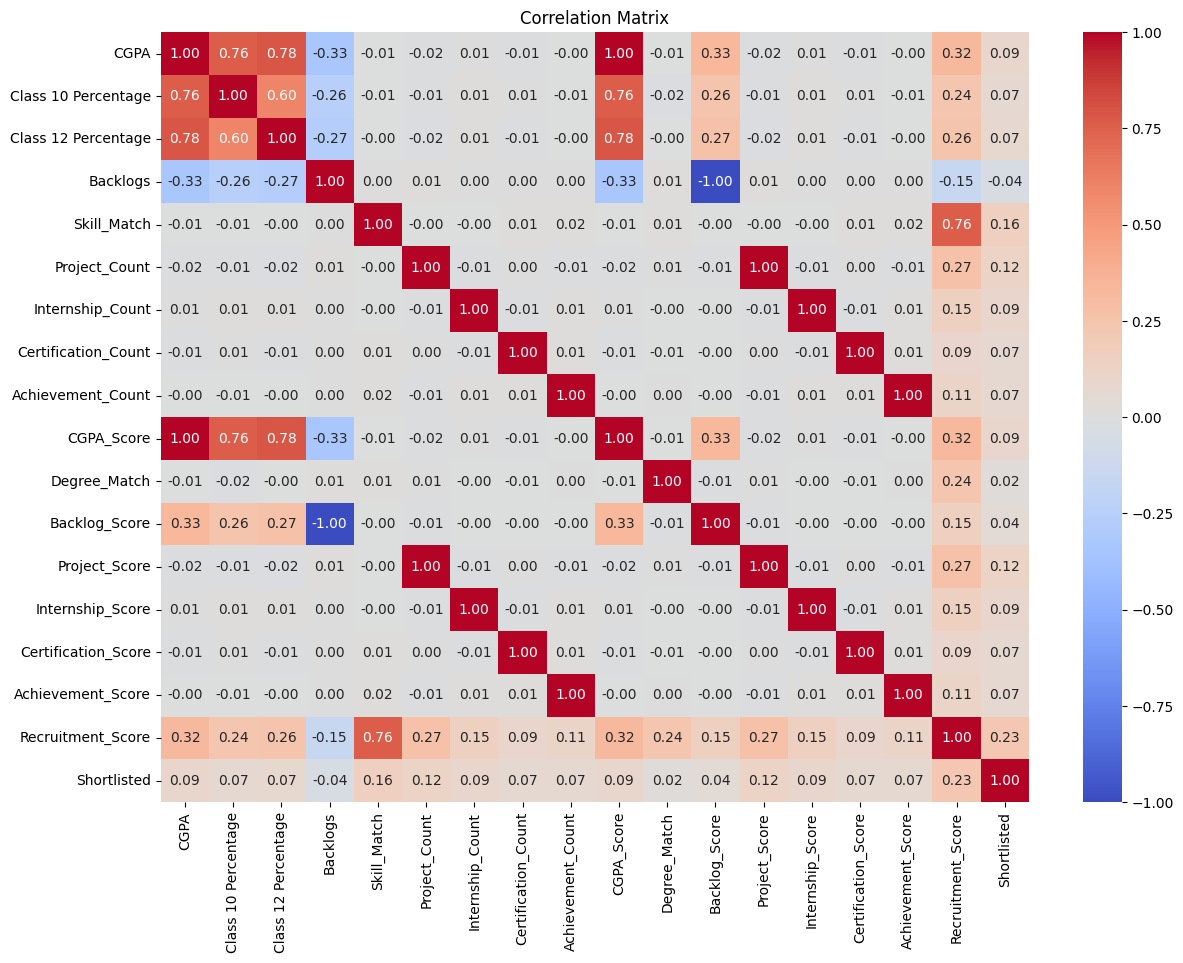

In [25]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

In [26]:
comparison = (
    df.groupby("Shortlisted")[
        [
            "CGPA",
            "Skill_Match",
            "Project_Count",
            "Internship_Count",
            "Certification_Count",
            "Achievement_Count",
            "Backlogs",
            "Recruitment_Score"
        ]
    ]
    .mean()
    .round(2)
)

comparison

,CGPA,Skill_Match,Project_Count,Internship_Count,Certification_Count,Achievement_Count,Backlogs,Recruitment_Score
Shortlisted,,,,,,,,
0,7.68,0.57,2.71,1.21,2.19,1.33,0.61,57.63
1,8.35,0.97,4.08,1.90,2.96,1.98,0.29,84.30


## EDA Conclusions

1. The dataset contains 16,508 application records.
2. The dataset represents 10,000 unique candidates applying to multiple job openings.
3. Shortlisting is performed independently for each job role.
4. The shortlist size is synthetically defined as approximately 3.5 times the number of available openings.
5. Recruitment Score is used for ranking candidates within each job.
6. Skill Match, CGPA, project experience, internship experience, certifications, achievements, degree compatibility, and backlog-related features contribute to the recruitment score.
7. The target variable is highly imbalanced because only a small proportion of applications are shortlisted.
8. Therefore, accuracy alone should not be used as the primary evaluation metric in the subsequent machine-learning stage.
9. Recruitment Score and Rank should not be used as model input features because they are directly involved in generating the Shortlisted target.